In [11]:
# Create a clean Conda environment for Medical 3D

import subprocess
from pathlib import Path

conda = "/usr/local/miniconda3/condabin/conda"
env_path = Path.home() / "medical3d_conda"

result = subprocess.run(
    [
        conda, "create",
        "-p", str(env_path),
        "-c", "conda-forge",
        "--override-channels",
        "python=3.10",
        "numpy",
        "nibabel",
        "matplotlib",
        "scipy",
        "scikit-image",
        "trimesh",
        "ipykernel",
        "-y"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stderr[-1500:])

Return code: 0



In [12]:
# Register the new Conda environment in Jupyter

import subprocess
from pathlib import Path

env_python = Path.home() / "medical3d_conda/bin/python"

result = subprocess.run(
    [
        str(env_python),
        "-m", "ipykernel", "install",
        "--user",
        "--name", "medical3d",
        "--display-name", "Python (Medical 3D)"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr)

Return code: 0
Installed kernelspec medical3d in /home/stud/nasrinke/.local/share/jupyter/kernels/medical3d




In [1]:
# Check the Python environment and working directory

import sys
from pathlib import Path

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Current directory:", Path.cwd())

Python version: 3.10.22 | packaged by conda-forge | (main, Oct  6 2026, 23:02:24) [GCC 14.4.0]
Python executable: /home/stud/nasrinke/medical3d_conda/bin/python
Current directory: /home/stud/nasrinke/projects/medical-3d-visualization/notebooks


In [2]:
# Check required Python packages

import importlib.util

packages = ["numpy", "nibabel", "matplotlib", "scipy"]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Missing'}")

numpy: Installed
nibabel: Installed
matplotlib: Installed
scipy: Installed


In [3]:
# Install NiBabel in the current Jupyter environment
%pip install nibabel

Note: you may need to restart the kernel to use updated packages.


In [5]:
# Check the existing Jupyter environment
from pathlib import Path

env_python = Path("/var/tmp/nasrinke_jupyter_clean/bin/python")

print("Environment exists:", env_python.exists())

Environment exists: False


In [6]:
# Define the medical image and segmentation mask directories

from pathlib import Path

BASE_DIR = Path.home() / "Thesis/Data/HCUCH/final-formatted/images"

IMAGE_DIR = BASE_DIR / "abdomen/train/images"
MASK_DIR = BASE_DIR / "abdomen_fixed/train/LN.masks"

print("Image directory exists:", IMAGE_DIR.exists())
print("Mask directory exists:", MASK_DIR.exists())

Image directory exists: True
Mask directory exists: True


In [7]:
# List available CT images and segmentation masks

image_files = sorted(IMAGE_DIR.glob("*.nii.gz"))
mask_files = sorted(MASK_DIR.glob("*.nii.gz"))

print("Number of CT images:", len(image_files))
print("Number of segmentation masks:", len(mask_files))

print("\nExample CT images:")
for file in image_files[:5]:
    print(file.name)

print("\nExample segmentation masks:")
for file in mask_files[:5]:
    print(file.name)

Number of CT images: 12
Number of segmentation masks: 12

Example CT images:
008_1.3.12.2.1107.5.1.4.83504.30000022101213201190600003679.nii.gz
008_1.3.12.2.1107.5.1.4.83504.30000022112912564272900009091.nii.gz
008_1.3.12.2.1107.5.1.4.83504.30000023011707404892200015805.nii.gz
008_1.3.12.2.1107.5.1.4.83885.30000022082507483231400011687.nii.gz
023_1.3.12.2.1107.5.1.4.83504.30000021072912214330400005557.nii.gz

Example segmentation masks:
008_1.3.12.2.1107.5.1.4.83504.30000022101213201190600003679.nii.gz
008_1.3.12.2.1107.5.1.4.83504.30000022112912564272900009091.nii.gz
008_1.3.12.2.1107.5.1.4.83504.30000023011707404892200015805.nii.gz
008_1.3.12.2.1107.5.1.4.83885.30000022082507483231400011687.nii.gz
023_1.3.12.2.1107.5.1.4.83504.30000021072912214330400005557.nii.gz


In [8]:
# Match CT images and segmentation masks by exact filename

image_lookup = {file.name: file for file in image_files}
mask_lookup = {file.name: file for file in mask_files}

common_names = sorted(
    set(image_lookup.keys()) & set(mask_lookup.keys())
)

print("Number of matching CT-mask pairs:", len(common_names))

for name in common_names[:10]:
    print(name)

Number of matching CT-mask pairs: 12
008_1.3.12.2.1107.5.1.4.83504.30000022101213201190600003679.nii.gz
008_1.3.12.2.1107.5.1.4.83504.30000022112912564272900009091.nii.gz
008_1.3.12.2.1107.5.1.4.83504.30000023011707404892200015805.nii.gz
008_1.3.12.2.1107.5.1.4.83885.30000022082507483231400011687.nii.gz
023_1.3.12.2.1107.5.1.4.83504.30000021072912214330400005557.nii.gz
023_1.3.12.2.1107.5.1.4.83504.30000021110312383749400012020.nii.gz
023_1.3.12.2.1107.5.1.4.83504.30000021120712090076800023840.nii.gz
025_1.3.12.2.1107.5.1.4.83504.30000023020613190381900014787.nii.gz
025_1.3.12.2.1107.5.1.4.83504.30000023031713195745100038136.nii.gz
025_1.3.12.2.1107.5.1.4.83885.30000022122012381826100005264.nii.gz


In [9]:
# Select one matching CT image and segmentation mask

if not common_names:
    raise ValueError("No matching CT-mask pairs were found.")

selected_name = common_names[0]

ct_path = image_lookup[selected_name]
mask_path = mask_lookup[selected_name]

print("Selected CT:", ct_path.name)
print("Selected Mask:", mask_path.name)

Selected CT: 008_1.3.12.2.1107.5.1.4.83504.30000022101213201190600003679.nii.gz
Selected Mask: 008_1.3.12.2.1107.5.1.4.83504.30000022101213201190600003679.nii.gz


In [10]:
# Load CT image and segmentation mask

import nibabel as nib
import numpy as np

ct_img = nib.load(str(ct_path))
mask_img = nib.load(str(mask_path))

ct_data = np.asarray(ct_img.dataobj)
mask_data = np.asarray(mask_img.dataobj)

print("CT shape:", ct_data.shape)
print("Mask shape:", mask_data.shape)

print("CT data type:", ct_data.dtype)
print("Mask data type:", mask_data.dtype)

CT shape: (512, 512, 162)
Mask shape: (512, 512, 162)
CT data type: float64
Mask data type: int16


In [24]:
# Report geometry differences before alignment

if not same_shape or not same_affine:
    print("CT and mask require geometry alignment.")
else:
    print("CT and mask are already aligned.")

CT and mask require geometry alignment.


In [18]:
# Check CT and mask orientation

import nibabel as nib
import numpy as np

ct_orientation = nib.aff2axcodes(ct_img.affine)
mask_orientation = nib.aff2axcodes(mask_img.affine)

print("CT orientation:", ct_orientation)
print("Mask orientation:", mask_orientation)

print("\nCT affine:")
print(ct_img.affine)

print("\nMask affine:")
print(mask_img.affine)

CT orientation: ('L', 'A', 'S')
Mask orientation: ('L', 'A', 'I')

CT affine:
[[  -0.671875    -0.           0.         177.6640625]
 [   0.           0.671875     0.         -20.6640625]
 [   0.           0.           2.5       -475.       ]
 [   0.           0.           0.           1.       ]]

Mask affine:
[[ -0.671875   -0.         -0.        177.6640625]
 [ -0.          0.671875    0.        -20.6640625]
 [  0.          0.         -2.5       -72.5      ]
 [  0.          0.          0.          1.       ]]


In [19]:
# Compare CT and mask geometry

relative_transform = np.linalg.inv(ct_img.affine) @ mask_img.affine

print("Mask-to-CT voxel transform:")
print(np.round(relative_transform, 4))

Mask-to-CT voxel transform:
[[  1.   0.   0.   0.]
 [  0.   1.   0.   0.]
 [  0.   0.  -1. 161.]
 [  0.   0.   0.   1.]]


In [20]:
# Align segmentation mask with CT orientation

mask_aligned = np.flip(mask_data, axis=2)

print("CT shape:", ct_data.shape)
print("Aligned mask shape:", mask_aligned.shape)

print("Original mask orientation:", nib.aff2axcodes(mask_img.affine))
print("Target CT orientation:", nib.aff2axcodes(ct_img.affine))

CT shape: (512, 512, 162)
Aligned mask shape: (512, 512, 162)
Original mask orientation: ('L', 'A', 'I')
Target CT orientation: ('L', 'A', 'S')


In [21]:
# Verify that the flipped mask matches the CT voxel grid

relative_transform = np.linalg.inv(ct_img.affine) @ mask_img.affine

expected_depth = mask_data.shape[2] - 1

alignment_ok = np.allclose(
    relative_transform,
    [
        [1, 0, 0, 0],
        [0, 1, 0, 0],
        [0, 0, -1, expected_depth],
        [0, 0, 0, 1]
    ],
    atol=1e-4
)

print("Alignment transformation verified:", alignment_ok)

assert ct_data.shape == mask_aligned.shape
assert alignment_ok, "Unexpected geometry transformation."

Alignment transformation verified: True


In [22]:
# Select the CT slice with the largest segmented area

binary_mask = mask_aligned > 0

mask_area_per_slice = np.count_nonzero(
    binary_mask,
    axis=(0, 1)
)

slice_idx = int(np.argmax(mask_area_per_slice))

if mask_area_per_slice[slice_idx] == 0:
    raise ValueError("The selected mask contains no segmented voxels.")

print("Selected slice:", slice_idx)
print("Segmented pixels:", mask_area_per_slice[slice_idx])

Selected slice: 132
Segmented pixels: 1289


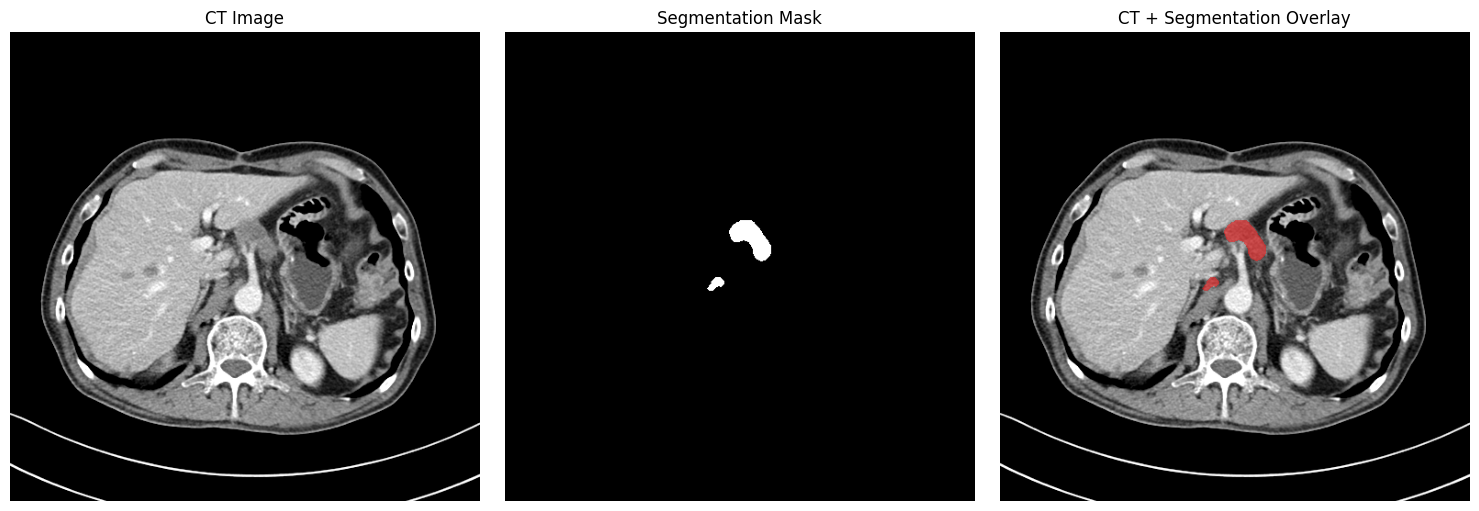

In [23]:
# Visualize CT, aligned segmentation mask, and overlay

import matplotlib.pyplot as plt

ct_slice = ct_data[:, :, slice_idx]
mask_slice = binary_mask[:, :, slice_idx]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# CT image
axes[0].imshow(
    ct_slice.T,
    cmap="gray",
    origin="lower",
    vmin=-135,
    vmax=215
)
axes[0].set_title("CT Image")

# Segmentation mask
axes[1].imshow(
    mask_slice.T,
    cmap="gray",
    origin="lower"
)
axes[1].set_title("Segmentation Mask")

# Overlay
axes[2].imshow(
    ct_slice.T,
    cmap="gray",
    origin="lower",
    vmin=-135,
    vmax=215
)

axes[2].imshow(
    np.ma.masked_where(~mask_slice.T, mask_slice.T),
    cmap="autumn",
    alpha=0.5,
    origin="lower"
)

axes[2].set_title("CT + Segmentation Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [25]:
# Save CT and segmentation visualization

from pathlib import Path

output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "ct_segmentation_overlay.png"

fig.savefig(output_path, dpi=150, bbox_inches="tight")

print("Saved:", output_path.resolve())

Saved: /home/stud/nasrinke/projects/medical-3d-visualization/results/figures/ct_segmentation_overlay.png
